###J-1. Verifikasi Lingkungan Kerja
Langkah ini bertujuan untuk mengetahui persis mesin yang dipakai, termasuk spesifikasi OS, versi Python, jumlah core CPU, serta ketersediaan RAM dan memori penyimpanan. Seluruh kesimpulan performa nantinya hanya berlaku untuk spesifikasi ini

In [2]:
import sys, platform, multiprocessing

print("Python    :", sys.version.split()[0])
print("OS        :", platform.platform())
print("CPU core  :", multiprocessing.cpu_count())

for nama in ["pandas", "numpy", "pyarrow", "matplotlib"]:
    try:
        mod = __import__(nama)
        print(f"{nama:11s}: {mod.__version__}")
    except ImportError:
        print(f"{nama:11s}: BELUM TERPASANG")

!free -h
!df -h /content
!java -version

Python    : 3.13.18
OS        : Linux-6.6.159+-x86_64-with-glibc2.39
CPU core  : 2
pandas     : 2.2.3
numpy      : 2.4.6
pyarrow    : 23.0.1
matplotlib : 3.10.0
               total        used        free      shared  buff/cache   available
Mem:            12Gi       1.7Gi       8.3Gi       2.5Mi       2.9Gi        10Gi
Swap:             0B          0B          0B
Filesystem      Size  Used Avail Use% Mounted on
overlay         108G  135M  108G   1% /
[0.014s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.014s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
openjdk version "21.0.12.1" 2026-08-18
OpenJDK Runtime Environment (build 21.0.12.1+1-1-24.04.4-Ubuntu)
OpenJDK 64-Bit Server VM (build 21.0.12.1+1-1-24.04.4-Ubuntu, mixed mode, sharing)


### J-2. Menghubungkan Google Drive dan menyiapkan struktur folder
Karena mesin virtual Colab bersifat sementara, kita perlu menghubungkan Google Drive sebagai tempat penyimpanan permanen. Folder kerja dan folder simpan juga dibuat agar artefak hasil dapat langsung tersimpan ke Drive.

In [3]:
from google.colab import drive
drive.mount("/content/drive")

import os
DIR_KERJA = "/content/data"
DIR_SIMPAN = "/content/drive/MyDrive/BigData/Praktikum1"

os.makedirs(DIR_KERJA, exist_ok=True)
os.makedirs(DIR_SIMPAN, exist_ok=True)

print(os.listdir(DIR_SIMPAN))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
['BD_B_P01_2311532021_StanleyLeonardDarmali.ipynb', 'yellow_tripdata_2023-01.parquet']


### J-3. Menyiapkan alat ukur waktu dan memori
Kita membuat fungsi utilitas kustom untuk mencatat durasi eksekusi serta memantau pemakaian RAM fisik (RSS). Alat ini akan menjadi bukti angka untuk membandingkan seberapa efisien setiap strategi pemrosesan data nantinya.

In [4]:
import time, os, psutil
proses = psutil.Process(os.getpid())
catatan = []

def rss_mb():
    return proses.memory_info().rss / 1024**2

def ukur(label, fungsi):
    """Menjalankan fungsi tanpa argumen, mencatat durasi dan pertumbuhan memori."""
    m0, t0 = rss_mb(), time.perf_counter()
    hasil = fungsi()
    detik = time.perf_counter() - t0
    delta = rss_mb() - m0

    catatan.append({"langkah": label, "detik": round(detik, 2), "delta_rss_mb": round(delta, 1)})
    print(f"[{label}] {detik:.2f} s | RSS delta: {delta:+.1f} MB")

    return hasil

### J-4. Mengunduh dataset dan inspeksi awal
Dataset NYC TLC Yellow Taxi diunduh secara terprogram menggunakan Python. Format filenya adalah Parquet, yang memungkinkan kita untuk mengintip metadata dan skema kolomnya tanpa perlu memuat seluruh isi file ke memori.

In [5]:
import urllib.request
import pyarrow.parquet as pq

URL = ("https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_2023-01.parquet")
PATH = os.path.join(DIR_KERJA, "yellow_tripdata_2023-01.parquet")

if not os.path.exists(PATH):
    ukur("unduh dataset", lambda: urllib.request.urlretrieve(URL, PATH))

print("Ukuran file:", round(os.path.getsize(PATH) / 1024**2, 1), "MB")

meta = pq.ParquetFile(PATH).metadata
print("Jumlah baris  :", f"{meta.num_rows:,}")
print("Jumlah kolom  :", meta.num_columns)
print("Row group     :", meta.num_row_groups)
print("Nama kolom    :", pq.ParquetFile(PATH).schema.names)

[unduh dataset] 0.33 s | RSS delta: +1.0 MB
Ukuran file: 45.5 MB
Jumlah baris  : 3,066,766
Jumlah kolom  : 19
Row group     : 1
Nama kolom    : ['VendorID', 'tpep_pickup_datetime', 'tpep_dropoff_datetime', 'passenger_count', 'trip_distance', 'RatecodeID', 'store_and_fwd_flag', 'PULocationID', 'DOLocationID', 'payment_type', 'fare_amount', 'extra', 'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge', 'total_amount', 'congestion_surcharge', 'airport_fee']


### J-4b. Jalur cadangan bila unduhan gagal
Fungsi ini disiapkan untuk membangkitkan data sintetis sebesar 5 juta baris jika dataset gagal diunduh dari internet karena kendala jaringan lab. (Tidak perlu dieksekusi jika data sudah berhasil terunduh di langkah J-4).

In [6]:
import numpy as np
import pandas as pd

def bangkitkan_sintetis(n=5_000_000, seed=42):
    rng = np.random.default_rng(seed)
    awal = pd.Timestamp("2023-01-01")
    pickup = awal + pd.to_timedelta(rng.integers(0, 31*24*60, n), unit="m")
    durasi = rng.integers(1, 90, n)

    return pd.DataFrame({
        "tpep_pickup_datetime": pickup,
        "tpep_dropoff_datetime": pickup + pd.to_timedelta(durasi, unit="m"),
        "passenger_count": rng.integers(1, 5, n).astype("float64"),
        "trip_distance": np.round(rng.gamma(2.0, 1.6, n), 2),
        "payment_type": rng.integers(1, 5, n).astype("int64"),
        "fare_amount": np.round(rng.gamma(4.0, 3.0, n), 2),
        "tip_amount": np.round(rng.gamma(1.5, 1.2, n), 2),
    }).assign(total_amount=lambda d: (d.fare_amount + d.tip_amount + 3.0).round(2))

if not os.path.exists(PATH):
    bangkitkan_sintetis().to_parquet(PATH, index=False)
    print("Dataset sintetis dibuat di", PATH)

### J-5. Memuat data dan mengukur biaya memorinya
Kita mengukur perbedaan memori saat membaca seluruh file vs. memuat kolom yang spesifik. Selanjutnya, tipe data dipersempit (downcast) untuk membuktikan bahwa kita bisa menghemat ruang memori secara signifikan di tahap awal.

In [7]:
import pandas as pd
import gc

KOLOM = ["tpep_pickup_datetime", "tpep_dropoff_datetime",
         "passenger_count", "trip_distance", "payment_type",
         "fare_amount", "tip_amount", "total_amount"]

penuh = ukur("baca semua kolom", lambda: pd.read_parquet(PATH))
print("Dimensi:", penuh.shape)
print("Memori", round(penuh.memory_usage(deep=True).sum() / 1024**2, 1), "MB")

del penuh
gc.collect()

df = ukur("baca kolom terpilih", lambda: pd.read_parquet(PATH, columns=KOLOM))
print("Dimensi:", df.shape)
print("Memori", round(df.memory_usage(deep=True).sum() / 1024**2, 1), "MB")

print(df.memory_usage(deep=True).sort_values(ascending=False) / 1024**2)

sebelum = df.memory_usage(deep=True).sum() / 1024**2

df["passenger_count"] = pd.to_numeric(df["passenger_count"], downcast="float")
df["payment_type"] = df["payment_type"].astype("int8").astype("category")

for kol in ["trip_distance", "fare_amount", "tip_amount", "total_amount"]:
    df[kol] = pd.to_numeric(df[kol], downcast="float")

sesudah = df.memory_usage(deep=True).sum() / 1024**2
print(f"{sebelum:.1f} MB -> {sesudah:.1f} MB (hemat {100*(1-sesudah/sebelum):.1f}%)")
print(df.dtypes)

[baca semua kolom] 1.30 s | RSS delta: +483.0 MB
Dimensi: (3066766, 19)
Memori 565.6 MB
[baca kolom terpilih] 1.00 s | RSS delta: +221.6 MB
Dimensi: (3066766, 8)
Memori 187.2 MB
tpep_pickup_datetime     23.397568
payment_type             23.397568
tpep_dropoff_datetime    23.397568
passenger_count          23.397568
trip_distance            23.397568
tip_amount               23.397568
fare_amount              23.397568
total_amount             23.397568
Index                     0.000126
dtype: float64
187.2 MB -> 119.9 MB (hemat 35.9%)
tpep_pickup_datetime     datetime64[us]
tpep_dropoff_datetime    datetime64[us]
passenger_count                 float32
trip_distance                   float64
payment_type                   category
fare_amount                     float32
tip_amount                      float32
total_amount                    float32
dtype: object


### J-6. Pemeriksaan kualitas data dan pembersihan (veracity)
Langkah ini menyaring nilai-nilai anomali seperti jarak 0, durasi negatif, atau tarif minus yang sering terjadi dalam data dunia nyata. Baris yang memenuhi threshold kelayakan logis disalin ke DataFrame baru bernama `bersih`.

In [8]:
df["durasi_menit"] = (df["tpep_dropoff_datetime"] - df["tpep_pickup_datetime"]).dt.total_seconds() / 60
print(df[["trip_distance", "durasi_menit", "total_amount"]].describe())
print("\nNilai kosong per kolom:\n", df.isna().sum())

anomali = {
    "jarak <= 0": (df["trip_distance"] <= 0).sum(),
    "durasi <= 0": (df["durasi_menit"] <= 0).sum(),
    "durasi > 180 menit": (df["durasi_menit"] > 180).sum(),
    "total_amount <= 0": (df["total_amount"] <= 0).sum(),
}

for k, v in anomali.items():
    print(f"{k:22s}: {v:,} baris ({100*v/len(df):.2f}%)")

layak = (
    (df["trip_distance"] > 0) & (df["trip_distance"] < 100) &
    df["durasi_menit"].between(1, 180) &
    (df["total_amount"] > 0)
)

bersih = df.loc[layak].copy()
print(f"{len(df):,} baris -> {len(bersih):,} baris (dibuang {len(df)-len(bersih):,})")

       trip_distance  durasi_menit  total_amount
count   3.066766e+06  3.066766e+06  3.066766e+06
mean    3.847342e+00  1.566900e+01  2.702039e+01
std     2.495838e+02  4.259435e+01  2.212666e+01
min     0.000000e+00 -2.920000e+01 -7.510000e+02
25%     1.060000e+00  7.116667e+00  1.540000e+01
50%     1.800000e+00  1.151667e+01  2.016000e+01
75%     3.330000e+00  1.830000e+01  2.870000e+01
max     2.589281e+05  1.002918e+04  1.169400e+03

Nilai kosong per kolom:
 tpep_pickup_datetime         0
tpep_dropoff_datetime        0
passenger_count          71743
trip_distance                0
payment_type                 0
fare_amount                  0
tip_amount                   0
total_amount                 0
durasi_menit                 0
dtype: int64
jarak <= 0            : 45,862 baris (1.50%)
durasi <= 0           : 1,121 baris (0.04%)
durasi > 180 menit    : 3,048 baris (0.10%)
total_amount <= 0     : 25,772 baris (0.84%)
3,066,766 baris -> 2,986,911 baris (dibuang 79,855)


### J-7. Memproses file lebih besar dari memori dengan chunking
Dataset disimpan sementara menjadi format CSV (uncompressed) untuk menyimulasikan data yang tidak muat di memori. File tersebut kemudian diproses menggunakan pendekatan membaca `chunksize` sehingga RAM tidak kelebihan beban.

In [9]:
CSV = os.path.join(DIR_KERJA, "trips.csv")
ukur("tulis CSV", lambda: bersih.to_csv(CSV, index=False))

print("Parquet:", round(os.path.getsize(PATH) / 1024**2, 1), "MB")
print("CSV    :", round(os.path.getsize(CSV) / 1024**2, 1), "MB")

def agregasi_bertahap(path, ukuran_chunk=500_000):
    jumlah_baris = 0
    total_nilai = 0.0
    per_jam = {}

    potongan = pd.read_csv(
        path,
        usecols=["tpep_pickup_datetime", "total_amount"],
        parse_dates=["tpep_pickup_datetime"],
        chunksize=ukuran_chunk
    )

    for chunk in potongan:
        jumlah_baris += len(chunk)
        total_nilai += chunk["total_amount"].sum()
        for jam, sub in chunk.groupby(chunk["tpep_pickup_datetime"].dt.hour):
            n, nilai = per_jam.get(jam, (0, 0.0))
            per_jam[jam] = (n + len(sub), nilai + sub["total_amount"].sum())

    return jumlah_baris, total_nilai, per_jam

baris, total, per_jam_chunk = ukur("agregasi chunking", lambda: agregasi_bertahap(CSV))
print(f"{baris:,} baris | rata-rata total_amount = {total/baris:.2f}")

[tulis CSV] 39.19 s | RSS delta: +5.4 MB
Parquet: 45.5 MB
CSV    : 226.2 MB
[agregasi chunking] 4.88 s | RSS delta: +19.0 MB
2,986,911 baris | rata-rata total_amount = 27.33


### J-8. Pendekatan terdistribusi: PySpark local mode
Pada tahap ini, agregasi diuji menggunakan ekosistem terdistribusi (Spark) mode lokal. Operasi lazy evaluation dalam Spark membantu melihat rencana eksekusi dan membandingkan performanya langsung dengan framework pandas pada data skala MB.

In [12]:
!pip install -q pyspark==3.5.1

from pyspark.sql import SparkSession, functions as F

spark = (SparkSession.builder
         .appName("BD-P01")
         .master("local[*]")
         .config("spark.driver.memory", "4g")
         .config("spark.sql.shuffle.partitions", "8")
         .getOrCreate())

spark.sparkContext.setLogLevel("WARN")
print("Spark:", spark.version)

sdf = spark.read.parquet(PATH)
sdf.printSchema()
print("Jumlah baris:", ukur("spark count", lambda: sdf.count()))

# FIX: Added .cast("timestamp") before .cast("long")
sdf_bersih = (sdf
    .withColumn("durasi_menit",
        (F.col("tpep_dropoff_datetime").cast("timestamp").cast("long") -
         F.col("tpep_pickup_datetime").cast("timestamp").cast("long")) / 60)
    .filter((F.col("trip_distance") > 0) & (F.col("trip_distance") < 100))
    .filter((F.col("durasi_menit") >= 1) & (F.col("durasi_menit") <= 180))
    .filter(F.col("total_amount") > 0)
)

hasil_spark = (sdf_bersih
    .withColumn("jam", F.hour("tpep_pickup_datetime"))
    .groupBy("jam")
    .agg(
        F.count("*").alias("jumlah"),
        F.round(F.avg("trip_distance"), 2).alias("rata_jarak"),
        F.round(F.avg("total_amount"), 2).alias("rata_tarif")
    )
    .orderBy("jam")
)

ukur("spark agregasi", lambda: hasil_spark.show(24, truncate=False))

sdf_bersih.createOrReplaceTempView("trips")
spark.sql("""
    SELECT payment_type,
           COUNT(*) AS jumlah,
           ROUND(AVG(total_amount), 2) AS rata_tarif,
           ROUND(AVG(tip_amount), 2) AS rata_tip
    FROM trips
    GROUP BY payment_type
    ORDER BY jumlah DESC
""").show()

hasil_spark.explain()
spark.stop()

Spark: 3.5.1
root
 |-- VendorID: long (nullable = true)
 |-- tpep_pickup_datetime: timestamp_ntz (nullable = true)
 |-- tpep_dropoff_datetime: timestamp_ntz (nullable = true)
 |-- passenger_count: double (nullable = true)
 |-- trip_distance: double (nullable = true)
 |-- RatecodeID: double (nullable = true)
 |-- store_and_fwd_flag: string (nullable = true)
 |-- PULocationID: long (nullable = true)
 |-- DOLocationID: long (nullable = true)
 |-- payment_type: long (nullable = true)
 |-- fare_amount: double (nullable = true)
 |-- extra: double (nullable = true)
 |-- mta_tax: double (nullable = true)
 |-- tip_amount: double (nullable = true)
 |-- tolls_amount: double (nullable = true)
 |-- improvement_surcharge: double (nullable = true)
 |-- total_amount: double (nullable = true)
 |-- congestion_surcharge: double (nullable = true)
 |-- airport_fee: double (nullable = true)

[spark count] 0.27 s | RSS delta: +0.0 MB
Jumlah baris: 3066766
+---+------+----------+----------+
|jam|jumlah|rata_j

### J-9. Agregasi akhir dengan pandas dan penyimpanan artefak
Menghitung agregasi akhir metrik perjalanan berdasarkan kelompok jam menggunakan pandas. Hasil tabel kemudian disalin dan diekspor ke Google Drive dalam bentuk format siap pakai (CSV dan Parquet).

In [13]:
bersih["jam"] = bersih["tpep_pickup_datetime"].dt.hour
agregasi = (bersih
    .groupby("jam")
    .agg(
        jumlah_perjalanan=("total_amount", "size"),
        rata_jarak=("trip_distance", "mean"),
        rata_durasi=("durasi_menit", "mean"),
        rata_tarif=("total_amount", "mean"),
        median_tarif=("total_amount", "median")
    )
    .round(2)
    .reset_index()
)

agregasi.to_csv(f"{DIR_SIMPAN}/agregasi_per_jam.csv", index=False)
agregasi.to_parquet(f"{DIR_SIMPAN}/agregasi_per_jam.parquet", index=False)
pd.DataFrame(catatan).to_csv(f"{DIR_SIMPAN}/pengukuran_kinerja.csv", index=False)

agregasi

,jam,jumlah_perjalanan,rata_jarak,rata_durasi,rata_tarif,median_tarif
0,0,82289,4.04,13.57,28.860001,21.600000
1,1,57766,3.53,12.63,26.450001,21.200001
2,2,40445,3.28,12.07,25.059999,20.520000
3,3,26146,3.58,12.15,26.260000,21.000000
4,4,16618,4.79,13.52,31.719999,22.700001
5,5,16940,6.03,14.70,36.750000,22.040001
6,6,42300,4.80,14.49,30.629999,18.480000
7,7,84569,3.69,14.42,26.889999,18.480000
8,8,114064,3.08,14.33,25.209999,19.100000
9,9,127988,3.09,14.23,25.510000,19.250000


### J-10. Visualisasi hasil
Membangun satu grafik dari data yang telah diagregasi menggunakan Matplotlib untuk menjawab dan mengkomunikasikan wawasan bisnis (trend perjalanan harian), yang kemudian disimpan menjadi gambar PNG.

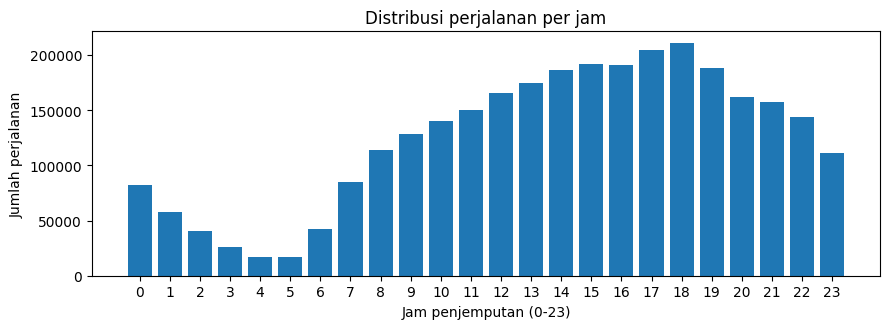

In [14]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.bar(agregasi["jam"], agregasi["jumlah_perjalanan"])
ax.set_xlabel("Jam penjemputan (0-23)")
ax.set_ylabel("Jumlah perjalanan")
ax.set_title("Distribusi perjalanan per jam")
ax.set_xticks(range(0, 24))

fig.tight_layout()
fig.savefig(f"{DIR_SIMPAN}/distribusi_per_jam.png", dpi=150)
plt.show()

### O. Studi Kasus (Penjadwalan Armada)
Membuat agregasi lanjutan untuk membandingkan perbedaan pola permintaan taksi dan profitabilitas (tarif per menit) antara hari kerja vs akhir pekan.

In [15]:
bersih["hari"] = bersih["tpep_pickup_datetime"].dt.day_name()
bersih["akhir_pekan"] = bersih["tpep_pickup_datetime"].dt.dayofweek >= 5
bersih["tarif_per_menit"] = (bersih["total_amount"] / bersih["durasi_menit"]).round(3)

ringkas = (bersih
    .groupby(["akhir_pekan", "jam"])
    .agg(
        jumlah=("total_amount", "size"),
        rata_durasi=("durasi_menit", "mean"),
        rata_tarif_per_menit=("tarif_per_menit", "mean")
    )
    .round(2)
)

ringkas.head(12)

jumlah  rata_durasi  rata_tarif_per_menit
akhir_pekan jam                                           
False       0     35351        14.10                  2.57
            1     17516        13.04                  2.66
            2      9452        12.23                  2.63
            3      6238        12.87                  2.72
            4      6192        14.79                  2.81
            5     12462        14.63                  2.82
            6     35728        14.57                  2.33
            7     74157        14.66                  2.07
            8     98431        14.82                  1.90
            9    103263        15.03                  1.90
            10   105228        15.24                  1.89
            11   108784        15.25                  1.86

### P. Latihan
Blok kode eksplorasi tambahan untuk menjawab tugas latihan analisis di dalam sesi lab, dari pengecekan trip distance ekstrim hingga studi trade-off chunking dan kompresi file parquet.

In [17]:
# Latihan 1: Hitung 5 nilai trip distance terbesar pada data bersih
print("--- Latihan 1 ---")
latihan_1 = bersih.nlargest(5, "trip_distance")
display(latihan_1)

# Latihan 2: Ulangi J-7 dengan chunksize 100k dan 1M
print("\n--- Latihan 2 ---")
b1, t1, p1 = ukur("chunk 100k", lambda: agregasi_bertahap(CSV, 100_000))
b2, t2, p2 = ukur("chunk 1M", lambda: agregasi_bertahap(CSV, 1_000_000))

# Latihan 3: Rata-rata persen tip per payment type
print("\n--- Latihan 3 ---")
# Menghindari pembagian dengan 0 dengan me-replace 0 menjadi NaN (pd.NA)
bersih["persen_tip"] = (bersih["tip_amount"] / bersih["fare_amount"].replace(0, pd.NA)) * 100
tip_per_payment = bersih.groupby("payment_type")["persen_tip"].mean()
print(tip_per_payment)

# Latihan 4: Simpan Parquet dengan dua kompresi berbeda
print("\n--- Latihan 4 ---")
ukur("Tulis Snappy", lambda: bersih.to_parquet(f"{DIR_SIMPAN}/trips_snappy.parquet", compression="snappy"))
ukur("Tulis Gzip", lambda: bersih.to_parquet(f"{DIR_SIMPAN}/trips_gzip.parquet", compression="gzip"))

# Latihan 5: Agregasi per jam Spark SQL
print("\n--- Latihan 5 ---")
from pyspark.sql import SparkSession, functions as F

# 1. Inisiasi ulang Spark
spark = SparkSession.builder.appName("Latihan5").master("local[*]").getOrCreate()
spark.sparkContext.setLogLevel("WARN")

# 2. Siapkan ulang Data dan TempView dengan perbaikan tipe data tanggal
sdf = spark.read.parquet(PATH)
sdf_bersih = (sdf
    .withColumn("durasi_menit",
        (F.col("tpep_dropoff_datetime").cast("timestamp").cast("long") -
         F.col("tpep_pickup_datetime").cast("timestamp").cast("long")) / 60)
    .filter((F.col("trip_distance") > 0) & (F.col("trip_distance") < 100))
    .filter((F.col("durasi_menit") >= 1) & (F.col("durasi_menit") <= 180))
    .filter(F.col("total_amount") > 0)
)
sdf_bersih.createOrReplaceTempView("trips")

# 3. Agregasi J-9 menggunakan Spark SQL
kueri_spark = spark.sql("""
    SELECT
        HOUR(tpep_pickup_datetime) AS jam,
        COUNT(*) AS jumlah_perjalanan_spark,
        ROUND(AVG(trip_distance), 2) AS rata_jarak_spark,
        ROUND(AVG(durasi_menit), 2) AS rata_durasi_spark,
        ROUND(AVG(total_amount), 2) AS rata_tarif_spark,
        ROUND(PERCENTILE_APPROX(total_amount, 0.5), 2) AS median_tarif_spark
    FROM trips
    GROUP BY HOUR(tpep_pickup_datetime)
    ORDER BY jam
""")

# 4. Konversi ke Pandas untuk dibandingkan dengan variabel 'agregasi' dari J-9
agregasi_spark = kueri_spark.toPandas()

# 5. Pembuktian selisih maksimum = 0
komparasi = pd.merge(agregasi, agregasi_spark, on="jam")
selisih_maksimum = (komparasi["jumlah_perjalanan"] - komparasi["jumlah_perjalanan_spark"]).abs().max()

print(f"Selisih maksimum jumlah perjalanan: {selisih_maksimum}")

if selisih_maksimum == 0:
    print("Kesimpulan: HASIL KONSISTEN. Tidak ada selisih jumlah baris antara perhitungan Pandas dan Spark SQL.")
else:
    print("Kesimpulan: Terdapat perbedaan jumlah.")

# Menampilkan sedikit sampel perbandingan kolom metrik lainnya
print("\nSampel perbandingan Median Tarif (Pandas vs Spark):")
print(komparasi[["jam", "median_tarif", "median_tarif_spark"]].head())

spark.stop()

--- Latihan 1 ---


,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,payment_type,fare_amount,tip_amount,total_amount,durasi_menit,jam,hari,akhir_pekan,tarif_per_menit,persen_tip
1748933,2023-01-19 16:29:36,2023-01-19 18:46:01,1.0,96.70,1,350.000000,50.0,440.750000,136.416667,16,Thursday,False,3.231,14.285714
526988,2023-01-07 04:29:56,2023-01-07 06:06:16,2.0,93.05,2,542.000000,0.0,564.049988,96.333333,4,Saturday,True,5.855,0.0
2402193,2023-01-26 04:55:45,2023-01-26 07:18:50,1.0,92.60,1,262.500000,20.0,312.799988,143.083333,4,Thursday,False,2.186,7.619048
2902389,2023-01-31 07:04:24,2023-01-31 09:32:54,1.0,92.00,1,334.100006,10.0,368.149994,148.500000,7,Tuesday,False,2.479,2.993116
927215,2023-01-11 14:23:55,2023-01-11 16:17:58,1.0,90.63,2,250.000000,0.0,272.299988,114.050000,14,Wednesday,False,2.388,0.0



--- Latihan 2 ---
[chunk 100k] 7.79 s | RSS delta: +0.9 MB
[chunk 1M] 3.86 s | RSS delta: +26.0 MB

--- Latihan 3 ---


/tmp/ipykernel_970/1295125378.py:15: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  tip_per_payment = bersih.groupby("payment_type")["persen_tip"].mean()


payment_type
0    20.223171
1    25.914261
2     0.002197
3     0.021737
4     0.146109
Name: persen_tip, dtype: object

--- Latihan 4 ---
[Tulis Snappy] 2.91 s | RSS delta: -0.5 MB
[Tulis Gzip] 72.58 s | RSS delta: +5.0 MB

--- Latihan 5 ---
Selisih maksimum jumlah perjalanan: 0
Kesimpulan: HASIL KONSISTEN. Tidak ada selisih jumlah baris antara perhitungan Pandas dan Spark SQL.

Sampel perbandingan Median Tarif (Pandas vs Spark):
   jam  median_tarif  median_tarif_spark
0    0     21.600000               21.60
1    1     21.200001               21.20
2    2     20.520000               20.52
3    3     21.000000               20.90
4    4     22.700001               22.70


### Q. Tugas Praktikum (Q1 & Q2): Perbandingan Dua Bulan
Mengunduh dataset bulan Juli 2023 (`yellow_tripdata_2023-07.parquet`), melakukan pembersihan dengan kriteria yang sama, lalu membandingkan pola distribusi perjalanan per jam antara bulan Januari dan Juli.

[unduh dataset juli] 0.34 s | RSS delta: +0.0 MB
Tabel Perbandingan Pola Per Jam (Januari vs Juli 2023):


,jam,jumlah_januari,jumlah_juli
0,0,82289,85987
1,1,57766,59980
2,2,40445,40812
3,3,26146,26000
4,4,16618,16637
5,5,16940,16913
6,6,42300,38422
7,7,84569,69358
8,8,114064,103647
9,9,127988,118788


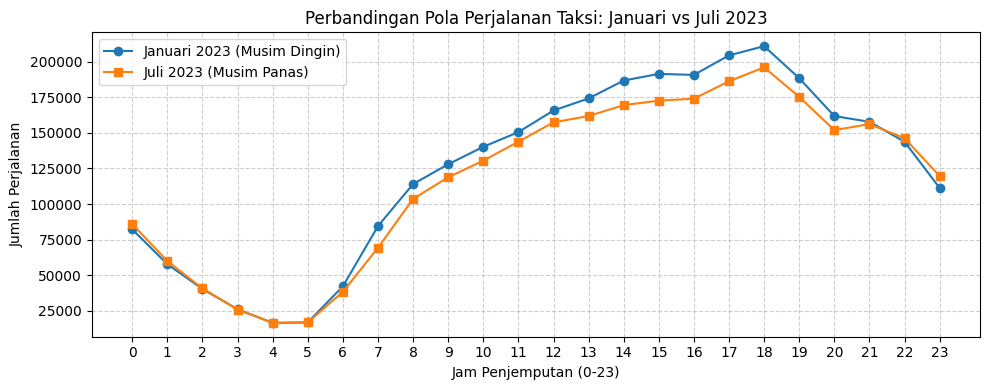

In [18]:
# --- Q1: Ganti Dataset (Bulan Juli 2023) ---
URL_JULI = "https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_2023-07.parquet"
PATH_JULI = os.path.join(DIR_KERJA, "yellow_tripdata_2023-07.parquet")

if not os.path.exists(PATH_JULI):
    ukur("unduh dataset juli", lambda: urllib.request.urlretrieve(URL_JULI, PATH_JULI))

# Membaca dataset Juli (langsung dengan kolom terpilih)
df_juli = pd.read_parquet(PATH_JULI, columns=["tpep_pickup_datetime", "tpep_dropoff_datetime", "trip_distance", "total_amount"])

# Kalkulasi durasi dan filter anomali yang sama persis dengan J-6
df_juli["durasi_menit"] = (df_juli["tpep_dropoff_datetime"] - df_juli["tpep_pickup_datetime"]).dt.total_seconds() / 60
layak_juli = (
    (df_juli["trip_distance"] > 0) & (df_juli["trip_distance"] < 100) &
    df_juli["durasi_menit"].between(1, 180) &
    (df_juli["total_amount"] > 0)
)
bersih_juli = df_juli.loc[layak_juli].copy()

# --- Q2: Bandingkan Dua Bulan ---
# Agregasi per jam untuk bulan Juli
bersih_juli["jam"] = bersih_juli["tpep_pickup_datetime"].dt.hour
agregasi_juli = bersih_juli.groupby("jam").size().reset_index(name='jumlah_juli')

# Gabungkan dengan data Januari (dari variabel 'agregasi' di J-9)
perbandingan = pd.merge(agregasi[["jam", "jumlah_perjalanan"]], agregasi_juli, on="jam")
perbandingan.rename(columns={"jumlah_perjalanan": "jumlah_januari"}, inplace=True)

print("Tabel Perbandingan Pola Per Jam (Januari vs Juli 2023):")
display(perbandingan)

# Visualisasi Perbandingan
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(perbandingan["jam"], perbandingan["jumlah_januari"], marker='o', label='Januari 2023 (Musim Dingin)')
ax.plot(perbandingan["jam"], perbandingan["jumlah_juli"], marker='s', label='Juli 2023 (Musim Panas)')

ax.set_xlabel("Jam Penjemputan (0-23)")
ax.set_ylabel("Jumlah Perjalanan")
ax.set_title("Perbandingan Pola Perjalanan Taksi: Januari vs Juli 2023")
ax.set_xticks(range(0, 24))
ax.legend()
ax.grid(True, linestyle='--', alpha=0.6)

fig.tight_layout()
fig.savefig(f"{DIR_SIMPAN}/perbandingan_jan_jul.png", dpi=150)
plt.show()